# Course 2: Mathematics for Machine Learning
## Session 11: Information theory for ML

**Goal:** compute entropy, cross-entropy, KL divergence and mutual information by hand and in NumPy, compare forward and reverse KL, and measure the perplexity of unigram and bigram character models on a short text.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### 1. By hand first: surprise and entropy
An outcome with probability $p$ carries $-\log_2 p$ bits of **surprise** (information): a fair coin's outcome carries 1 bit, an event with probability 1/8 carries 3 bits. The **entropy** of a distribution is the average surprise, $H(p) = -\sum_i p_i \log_2 p_i$ (Shannon 1948). With the natural logarithm the unit is the **nat**; 1 nat = $1/\ln 2 \approx 1.443$ bits.

On paper: the entropy of (1/2, 1/4, 1/8, 1/8), and of a coin with $P(\text{heads}) = 0.9$. Then run the cell. It also encodes 10,000 random symbols with the code a → 0, b → 10, c → 110, d → 111: Shannon's source coding theorem says no code can use fewer than $H$ bits per symbol on average, and this one achieves it.

H(1/2, 1/4, 1/8, 1/8) = 1.7500 bits = 1.2130 nats (scipy: 1.7500 bits)
H(coin 0.5) = 1.0000 bits; H(coin 0.9) = 0.4690 bits; H(uniform on 6) = 2.5850 bits = log2(6) = 2.5850
average code length over 10,000 symbols: 1.7515 bits (entropy 1.7500)


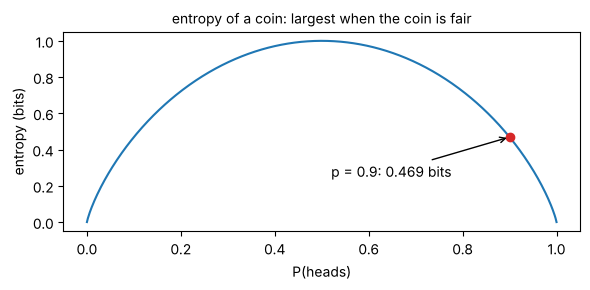

In [1]:
import math, time
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, optimize, stats
from scipy.special import xlogy

t_start = time.time()
np.random.seed(0)

def entropy(p, base=2):
    p = np.asarray(p, dtype=float)
    return -xlogy(p, p).sum() / math.log(base)                 # xlogy(0, 0) = 0, so zero probabilities are fine

p4 = np.array([1/2, 1/4, 1/8, 1/8])
print(f"H(1/2, 1/4, 1/8, 1/8) = {entropy(p4):.4f} bits = {entropy(p4, math.e):.4f} nats (scipy: {stats.entropy(p4, base=2):.4f} bits)")
print(f"H(coin 0.5) = {entropy([0.5, 0.5]):.4f} bits; H(coin 0.9) = {entropy([0.9, 0.1]):.4f} bits; "
      f"H(uniform on 6) = {entropy(np.full(6, 1/6)):.4f} bits = log2(6) = {math.log2(6):.4f}")

rng = np.random.default_rng(0)
symbols = rng.choice(4, size=10000, p=p4)
code_len = np.array([1, 2, 3, 3])                               # a -> 0, b -> 10, c -> 110, d -> 111
print(f"average code length over 10,000 symbols: {code_len[symbols].mean():.4f} bits (entropy {entropy(p4):.4f})")

pp = np.linspace(0, 1, 501)
plt.figure(figsize=(6, 3))
plt.plot(pp, [entropy([q, 1 - q]) for q in pp])
plt.plot([0.9], [entropy([0.9, 0.1])], "o", color="C3"); plt.annotate("p = 0.9: 0.469 bits", (0.9, 0.469), (0.52, 0.25), arrowprops=dict(arrowstyle="->"))
plt.xlabel("P(heads)"); plt.ylabel("entropy (bits)"); plt.title("entropy of a coin: largest when the coin is fair", fontsize=10)
plt.tight_layout(); plt.show()

### 2. Cross-entropy and KL divergence
The **cross-entropy** $H(p, q) = -\sum_i p_i \log q_i$ is the average code length when the data come from $p$ but the code was designed for $q$. The **Kullback–Leibler (KL) divergence** $\text{KL}(p\|q) = \sum_i p_i \log(p_i/q_i)$ is the extra cost, so

$$H(p, q) = H(p) + \text{KL}(p\|q).$$

KL is never negative and is 0 only when $p = q$ (Gibbs' inequality; Cover & Thomas 2006). It is **not symmetric** and does not satisfy the triangle inequality, so it is not a distance. We check all of this numerically, including on 10,000 random pairs of distributions.

In [2]:
def cross_entropy(p, q, base=2):
    p, q = np.asarray(p, float), np.asarray(q, float)
    with np.errstate(divide="ignore"):
        return -xlogy(p, q).sum() / math.log(base)              # +inf if q = 0 where p > 0
def kl(p, q, base=2):
    return cross_entropy(p, q, base) - entropy(p, base)

p, q = np.array([0.5, 0.5]), np.array([0.25, 0.75])
print(f"p = {p}, q = {q}: H(p) = {entropy(p):.4f}, H(p, q) = {cross_entropy(p, q):.4f}, KL(p||q) = {kl(p, q):.4f}, KL(q||p) = {kl(q, p):.4f} bits")
print(f"a fixed 2-bit code for (1/2, 1/4, 1/8, 1/8): H(p, uniform) = {cross_entropy(p4, np.full(4, 0.25)):.4f} bits, "
      f"wasting KL = {kl(p4, np.full(4, 0.25)):.4f} bits per symbol")
print(f"p = (1, 0), q = (1/2, 1/2): KL(p||q) = {kl([1, 0], [0.5, 0.5]):.4f} bit, KL(q||p) = {kl([0.5, 0.5], [1, 0])}")

rng = np.random.default_rng(1)
P, Q = rng.dirichlet(np.ones(5), 10000), rng.dirichlet(np.ones(5), 10000)
gap = max(abs(cross_entropy(a, b) - entropy(a) - np.sum(xlogy(a, a / b)) / math.log(2)) for a, b in zip(P[:1000], Q[:1000]))
kls = np.array([kl(a, b) for a, b in zip(P, Q)])
print(f"random pairs: largest |H(p, q) - H(p) - sum p log(p/q)| = {gap:.1e}; smallest KL over 10,000 pairs {kls.min():.4f} (never negative)")

bern = lambda a: np.array([a, 1 - a])
a, b, c = bern(0.9), bern(0.5), bern(0.1)
print(f"triangle inequality fails: KL(0.9||0.1) = {kl(a, c):.3f} bits > KL(0.9||0.5) + KL(0.5||0.1) = {kl(a, b):.3f} + {kl(b, c):.3f} = {kl(a, b) + kl(b, c):.3f}")

p = [0.5 0.5], q = [0.25 0.75]: H(p) = 1.0000, H(p, q) = 1.2075, KL(p||q) = 0.2075, KL(q||p) = 0.1887 bits
a fixed 2-bit code for (1/2, 1/4, 1/8, 1/8): H(p, uniform) = 2.0000 bits, wasting KL = 0.2500 bits per symbol
p = (1, 0), q = (1/2, 1/2): KL(p||q) = 1.0000 bit, KL(q||p) = inf


random pairs: largest |H(p, q) - H(p) - sum p log(p/q)| = 1.8e-15; smallest KL over 10,000 pairs 0.0070 (never negative)
triangle inequality fails: KL(0.9||0.1) = 2.536 bits > KL(0.9||0.5) + KL(0.5||0.1) = 0.531 + 0.737 = 1.268


### 3. Minimizing cross-entropy fits the model
Training data define an empirical distribution $\hat p$. A model $q_\theta$'s average negative log-likelihood (NLL) on the data is exactly $H(\hat p, q_\theta) = H(\hat p) + \text{KL}(\hat p\|q_\theta)$. $H(\hat p)$ does not depend on $\theta$, so minimizing the cross-entropy loss is minimizing the KL divergence from the data to the model, and it is maximum likelihood (session 7).

We draw 200 samples from a 5-class distribution, then fit $q = \text{softmax}(\theta)$ by gradient descent on the cross-entropy. The gradient with respect to the logits is simply $q - \hat p$.

In [3]:
rng = np.random.default_rng(2)
p_true = np.array([0.4, 0.25, 0.15, 0.12, 0.08])
data = rng.choice(5, size=200, p=p_true)
p_hat = np.bincount(data, minlength=5) / len(data)
softmax = lambda t: np.exp(t - t.max()) / np.exp(t - t.max()).sum()

theta = np.zeros(5)
for step in range(501):
    qm = softmax(theta)
    if step in (0, 10, 100, 500):
        nll = -np.mean(np.log(qm[data])) / math.log(2)
        print(f"step {step:3d}: average NLL {nll:.4f} bits = H(p_hat, q) {cross_entropy(p_hat, qm):.4f}; KL(p_hat||q) {kl(p_hat, qm):.6f}")
    theta -= 1.0 * (qm - p_hat)                                 # gradient of the cross-entropy with respect to the logits
print(f"empirical p_hat {p_hat}; fitted q {np.round(softmax(theta), 4)}; H(p_hat) = {entropy(p_hat):.4f} bits")

step   0: average NLL 2.3219 bits = H(p_hat, q) 2.3219; KL(p_hat||q) 0.202783
step  10: average NLL 2.1228 bits = H(p_hat, q) 2.1228; KL(p_hat||q) 0.003672
step 100: average NLL 2.1191 bits = H(p_hat, q) 2.1191; KL(p_hat||q) 0.000000
step 500: average NLL 2.1191 bits = H(p_hat, q) 2.1191; KL(p_hat||q) 0.000000
empirical p_hat [0.385 0.255 0.155 0.12  0.085]; fitted q [0.385 0.255 0.155 0.12  0.085]; H(p_hat) = 2.1191 bits


### 4. KL is not symmetric: forward and reverse KL
For two Gaussians, $\text{KL}(N(\mu_1, \sigma_1^2)\|N(\mu_2, \sigma_2^2)) = \ln\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac12$ nats. We check it by numerical integration for $p = N(0, 1)$ and $q = N(1, 2^2)$.

Then we fit one Gaussian $q$ to a two-bump mixture $p = \frac12 N(-2, 0.6^2) + \frac12 N(2, 0.6^2)$ in two ways. **Forward KL**, $\text{KL}(p\|q)$, is what maximum likelihood minimizes: $q$ is punished wherever $p$ has mass that $q$ misses, so it spreads to cover both bumps ("mass-covering"). **Reverse KL**, $\text{KL}(q\|p)$, is what variational inference and VAEs minimize: $q$ is punished for putting mass where $p$ has little, so it sits on one bump ("mode-seeking") (Bishop 2006, section 10.1).

p = N(0, 1), q = N(1, 4): KL(p||q) = 0.4431 nats (integration 0.4431); KL(q||p) = 1.3069 nats (integration 1.3069)


forward KL(p||q): mu = +0.0000, sigma = 2.0881; at this q, KL(p||q) = 0.5552 and KL(q||p) = 1.2731 nats
reverse KL(q||p): mu = +1.9971, sigma = 0.6049; at this q, KL(p||q) = 10.2256 and KL(q||p) = 0.6918 nats
moment matching predicts the forward fit: mean 0, sigma = sqrt(0.6^2 + 2^2) = 2.0881; ln 2 = 0.6931


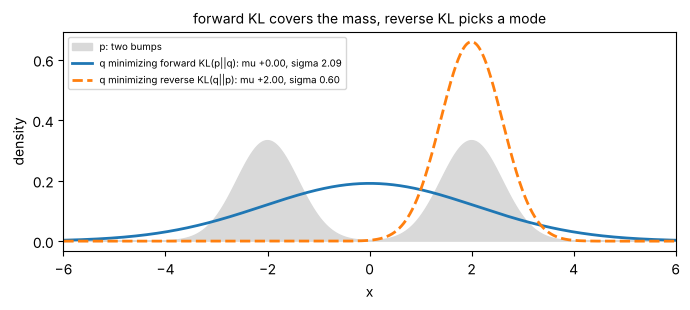

In [4]:
def kl_gauss(m1, s1, m2, s2):
    return math.log(s2 / s1) + (s1**2 + (m1 - m2) ** 2) / (2 * s2**2) - 0.5
def kl_numeric(lp, lq):                                          # KL(p||q) in nats from log densities, by integration
    return integrate.quad(lambda x: np.exp(lp(x)) * (lp(x) - lq(x)), -np.inf, np.inf)[0]
lp1, lq1 = (lambda x: stats.norm.logpdf(x, 0, 1)), (lambda x: stats.norm.logpdf(x, 1, 2))
print(f"p = N(0, 1), q = N(1, 4): KL(p||q) = {kl_gauss(0, 1, 1, 2):.4f} nats (integration {kl_numeric(lp1, lq1):.4f}); "
      f"KL(q||p) = {kl_gauss(1, 2, 0, 1):.4f} nats (integration {kl_numeric(lq1, lp1):.4f})")

xg = np.linspace(-10, 10, 8001); dx = xg[1] - xg[0]
log_mix = np.logaddexp(np.log(0.5) + stats.norm.logpdf(xg, -2, 0.6), np.log(0.5) + stats.norm.logpdf(xg, 2, 0.6))
def kl_forward(t):                                               # KL(p || q) with q = N(mu, sigma^2), t = (mu, log sigma)
    lq = stats.norm.logpdf(xg, t[0], np.exp(t[1])); return np.sum(np.exp(log_mix) * (log_mix - lq)) * dx
def kl_reverse(t):                                               # KL(q || p)
    lq = stats.norm.logpdf(xg, t[0], np.exp(t[1])); return np.sum(np.exp(lq) * (lq - log_mix)) * dx
fits = {}
for name, fun in [("forward KL(p||q)", kl_forward), ("reverse KL(q||p)", kl_reverse)]:
    r = optimize.minimize(fun, x0=[0.5, 0.0], method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-12, "maxiter": 2000})
    mu = round(float(r.x[0]), 6) + 0.0                            # + 0.0 turns -0.0 into 0.0 for printing
    fits[name] = (mu, np.exp(r.x[1]))
    print(f"{name}: mu = {mu:+.4f}, sigma = {np.exp(r.x[1]):.4f}; at this q, KL(p||q) = {kl_forward(r.x):.4f} and KL(q||p) = {kl_reverse(r.x):.4f} nats")
print(f"moment matching predicts the forward fit: mean 0, sigma = sqrt(0.6^2 + 2^2) = {math.sqrt(0.36 + 4):.4f}; ln 2 = {math.log(2):.4f}")

plt.figure(figsize=(7, 3.2))
plt.fill_between(xg, np.exp(log_mix), color="0.85", label="p: two bumps")
for (name, (mu, s)), ls in zip(fits.items(), ["-", "--"]):
    plt.plot(xg, stats.norm.pdf(xg, mu, s), ls, lw=2, label=f"q minimizing {name}: mu {mu:+.2f}, sigma {s:.2f}")
plt.xlim(-6, 6); plt.xlabel("x"); plt.ylabel("density"); plt.title("forward KL covers the mass, reverse KL picks a mode", fontsize=10)
plt.legend(fontsize=7); plt.tight_layout(); plt.show()

### 5. Mutual information
The **mutual information** between $X$ and $Y$ is how much knowing one reduces the uncertainty about the other:

$$I(X; Y) = H(X) + H(Y) - H(X, Y) = \text{KL}\big(p(x, y)\,\|\,p(x)p(y)\big) \ge 0,$$

with equality exactly when $X$ and $Y$ are independent. Unlike correlation, it detects any kind of dependence. We compute it exactly for three small joint tables (a copy, independent bits, and a channel that flips the bit with probability 0.1), then estimate it from 20,000 samples of continuous pairs by binning into a 20 × 20 histogram and with scikit-learn's nearest-neighbour estimator.

Y = X (a copy)                     : I = 1.0000 bits; KL(joint || product of marginals) = 1.0000
independent bits                   : I = 0.0000 bits; KL(joint || product of marginals) = 0.0000
Y = X flipped with probability 0.1 : I = 0.5310 bits; KL(joint || product of marginals) = 0.5310
check: 1 - H(0.1) = 0.5310 bits
Y = X + noise       : correlation +0.985; mutual information 2.279 bits (20 x 20 bins), 2.416 bits (nearest neighbours)


Y = X^2 + noise     : correlation -0.010; mutual information 1.996 bits (20 x 20 bins), 2.309 bits (nearest neighbours)
Y independent of X  : correlation +0.005; mutual information 0.014 bits (20 x 20 bins), 0.012 bits (nearest neighbours)


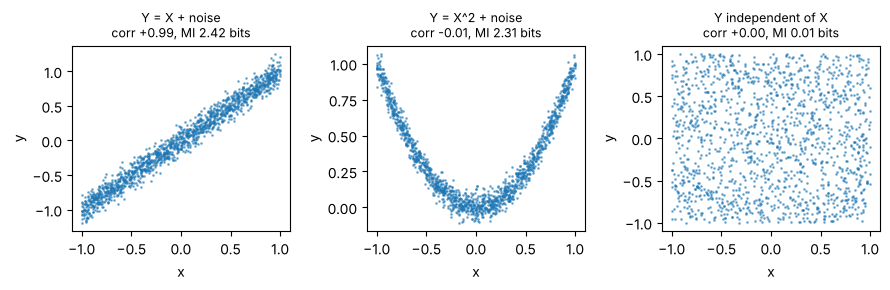

In [5]:
from sklearn.feature_selection import mutual_info_regression

def mutual_info(joint):
    joint = np.asarray(joint, float)
    return entropy(joint.sum(1)) + entropy(joint.sum(0)) - entropy(joint.ravel())
for name, J in [("Y = X (a copy)", [[0.5, 0], [0, 0.5]]), ("independent bits", [[0.25, 0.25], [0.25, 0.25]]),
                ("Y = X flipped with probability 0.1", [[0.45, 0.05], [0.05, 0.45]])]:
    J = np.array(J)
    print(f"{name:35s}: I = {mutual_info(J):.4f} bits; KL(joint || product of marginals) = {kl(J.ravel(), np.outer(J.sum(1), J.sum(0)).ravel()):.4f}")
print(f"check: 1 - H(0.1) = {1 - entropy([0.1, 0.9]):.4f} bits")

rng = np.random.default_rng(3)
n = 20000; xs = rng.uniform(-1, 1, n)
pairs = {"Y = X + noise": xs + rng.normal(0, 0.1, n), "Y = X^2 + noise": xs**2 + rng.normal(0, 0.05, n), "Y independent of X": rng.uniform(-1, 1, n)}
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for a, (name, ys) in zip(ax, pairs.items()):
    corr = np.corrcoef(xs, ys)[0, 1]
    H2, _, _ = np.histogram2d(xs, ys, bins=20); mi_bins = mutual_info(H2 / n)
    mi_knn = mutual_info_regression(xs[:, None], ys, random_state=0)[0] / math.log(2)
    print(f"{name:20s}: correlation {corr:+.3f}; mutual information {mi_bins:.3f} bits (20 x 20 bins), {mi_knn:.3f} bits (nearest neighbours)")
    a.plot(xs[:1500], ys[:1500], ".", ms=2, alpha=0.5)
    a.set_title(f"{name}\ncorr {corr:+.2f}, MI {mi_knn:.2f} bits", fontsize=9); a.set_xlabel("x"); a.set_ylabel("y")
plt.tight_layout(); plt.show()

### 6. Perplexity of character language models
A language model gives each next character a probability. Its cross-entropy on held-out text is the average $-\log_2 q(\text{next character} \mid \text{context})$ in **bits per character**, and its **perplexity** is $2^{\text{bits per character}}$ (equal to $e^{\text{nats per character}}$): a perplexity of $k$ means the model is as unsure as if it chose uniformly among $k$ characters. Course 5 session 7 and Course 4 use it to compare language models.

The text below (written for this notebook, about 2,500 characters) is lowercased; the first 80% is for training and the last 20% for testing. We compare three models: **uniform** over the $V$ characters, **unigram** $q(c)$ from character counts, and **bigram** $q(c \mid \text{previous character})$. Both count models use add-one smoothing, $(\text{count} + 1)/(\text{total} + V)$, so no test character gets probability 0. This is the posterior mean under a uniform Dirichlet prior: session 7's coin, with $V$ sides.

In [6]:
TEXT = 'Machine learning is built from a small set of mathematical ideas. A vector stores the numbers that describe one example, and a matrix stores a whole data set. A model is a function with parameters, and training changes the parameters so that the model fits the data. The loss tells us how badly the model fits. For a classifier the loss is the cross entropy, which is the negative log likelihood of the correct labels. To lower the loss we follow the gradient downhill, one small step at a time. The size of each step is the learning rate. If the step is too large the loss grows, and if it is too small the training takes a very long time. Probability tells us how to describe uncertainty. A coin that lands heads seven times in ten flips suggests that the chance of heads is close to seven in ten, but with only ten flips we should not be too sure. Statistics turns this feeling into numbers, such as a standard error or a confidence interval. Information theory measures surprise. A rare event carries more information than a common one, and the entropy of a distribution is the average surprise. When a model predicts the next letter of a text, a good model is rarely surprised, and its perplexity is low. Linear algebra gives us the tools to compute all of this quickly. A computer can multiply large matrices in a fraction of a second, so a model can look at thousands of examples at once. Numerical methods remind us that computers round every number, and that a careless formula can turn a small rounding error into a large one. Graphs describe how things are connected, such as friends in a social network, pages on the web or atoms in a molecule. A graph can be stored as a matrix, and then the same linear algebra applies. Many students learn these subjects in separate courses and never see how they fit together. In machine learning they meet in every line of code. The best way to learn them is to compute a small example by hand, then check the answer with a short program, and then ask what would change if the data were larger or the numbers were less friendly. A teacher can help by choosing examples that are small enough to work on paper but rich enough to show the idea. A student can help herself by writing down what she expects before she runs the code, because a surprise is the moment when learning happens. Over time the notation stops looking strange, and the equations start to read like sentences that say what the program does.'

text = " ".join(TEXT.lower().split())
chars = sorted(set(text)); V = len(chars); ix = {ch: i for i, ch in enumerate(chars)}
ids = np.array([ix[ch] for ch in text])
cut = int(0.8 * len(ids)); train, test = ids[:cut], ids[cut:]
print(f"{len(text)} characters, vocabulary V = {V}: {''.join(chars)!r}; train {len(train)}, test {len(test)}")

uni = (np.bincount(train, minlength=V) + 1) / (len(train) + V)
big_counts = np.ones((V, V))                                     # add-one smoothing
np.add.at(big_counts, (train[:-1], train[1:]), 1)
big = big_counts / big_counts.sum(axis=1, keepdims=True)
prev = np.r_[train[-1], test[:-1]]                                 # the character before each test character

results = {"uniform": np.full(len(test), math.log2(V)), "unigram": -np.log2(uni[test]), "bigram": -np.log2(big[prev, test])}
for name, bits in results.items():
    print(f"{name:8s}: {bits.mean():.4f} bits per character, perplexity {2 ** bits.mean():.2f}")
print(f"the same bigram model on its own training text: {np.mean(-np.log2(big[train[:-1], train[1:]])):.4f} bits per character")

print("by hand: a model gives the test tokens probabilities 1/2, 1/4, 1/8, 1/4 ->",
      f"{np.mean(-np.log2([1/2, 1/4, 1/8, 1/4])):.1f} bits per token, perplexity {2 ** np.mean(-np.log2([1/2, 1/4, 1/8, 1/4])):.1f}")
after_t = big[ix["t"]]; top = np.argsort(after_t)[::-1][:3]
print("bigram model, most likely characters after 't':", ", ".join(f"{chars[k]!r} {after_t[k]:.3f}" for k in top))
print(f"runtime so far {time.time() - t_start:.0f} s")

2458 characters, vocabulary V = 29: ' ,.abcdefghijklmnopqrstuvwxyz'; train 1966, test 492
uniform : 4.8580 bits per character, perplexity 29.00
unigram : 4.1504 bits per character, perplexity 17.76
bigram  : 3.6055 bits per character, perplexity 12.17
the same bigram model on its own training text: 3.3818 bits per character
by hand: a model gives the test tokens probabilities 1/2, 1/4, 1/8, 1/4 -> 2.0 bits per token, perplexity 4.0
bigram model, most likely characters after 't': 'h' 0.276, ' ' 0.122, 'e' 0.116
runtime so far 1 s


### 7. A pretrained model's perplexity (NOT RUN here)
GPT-2 (124 million parameters) reads subword tokens, not characters, so to compare it with the models above, convert its loss to bits per character. It needs a download.

In [ ]:
# NOT RUN: needs the transformers library and a download of GPT-2 (about 500 MB)
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer
tok = AutoTokenizer.from_pretrained("gpt2"); lm = AutoModelForCausalLM.from_pretrained("gpt2").eval()
test_text = TEXT[int(0.8 * len(TEXT)):]
enc = tok(test_text, return_tensors="pt").input_ids
with torch.no_grad():
    loss = lm(enc, labels=enc).loss.item()                       # mean nats per predicted token (the first token is not predicted)
n_pred = enc.shape[1] - 1
print(f"GPT-2: {loss:.3f} nats per token, perplexity {math.exp(loss):.1f} per token, "
      f"about {loss * n_pred / math.log(2) / len(test_text):.3f} bits per character")

### 8. Exercises

In [7]:
# TODO: a trigram model q(c | two previous characters) with add-alpha smoothing, (count + alpha) / (total + alpha * V).
# Hold out the last 20% of the TRAINING characters as a validation set, choose alpha from (0.01, 0.03, 0.1, 0.3, 1),
# then report bits per character on the test set. Is it better than the bigram model? Why might it not be, on so little text?
def trigram_bits_per_char():
    return None          # replace with your code

r = trigram_bits_per_char()
print("not done yet" if r is None else f"trigram: {r:.4f} bits per character")

not done yet


In [8]:
# TODO: which pixels tell you the digit? For load_digits, compute the mutual information between each of the 64 pixels
# and the label with sklearn.feature_selection.mutual_info_classif (random_state=0), show it as an 8 x 8 image, and
# compare it with the 8 x 8 image of the pixel variances. Return the 64 values in bits.
def pixel_label_mi():
    return None          # replace with your code

r = pixel_label_mi()
print("not done yet" if r is None else np.round(np.asarray(r).reshape(8, 8), 2))

not done yet


### What to notice
(Written from the run above; your numbers will match if you keep the seeds.)

1. **The hand values matched.** $H(1/2, 1/4, 1/8, 1/8)$ = 1.7500 bits (1.2130 nats) and a coin with $P(\text{heads}) = 0.9$ has 0.4690 bits. The prefix code used 1.7515 bits per symbol on 10,000 random symbols, right at the entropy.
2. **The decomposition held, and KL is not a distance.** For $p = (1/2, 1/2)$ and $q = (1/4, 3/4)$: $H(p, q)$ = 1.2075 = 1 + 0.2075 bits, while $\text{KL}(q\|p)$ = 0.1887. A fixed 2-bit code for (1/2, 1/4, 1/8, 1/8) wasted exactly KL = 0.2500 bits per symbol. $\text{KL}((1, 0)\|(1/2, 1/2))$ = 1 bit, but the reverse is infinite. Over 10,000 random pairs the smallest KL was 0.0070 (never negative), and the triangle inequality failed: 2.536 > 0.531 + 0.737 = 1.268 bits.
3. **Minimizing cross-entropy recovered the data's frequencies.** Gradient descent on the logits drove $\text{KL}(\hat p\|q)$ from 0.2028 to 0.000000 by step 100, and the cross-entropy fell to $H(\hat p)$ = 2.1191 bits, the lowest any model can reach on these data.
4. **Forward and reverse KL give different fits.** For $N(0, 1)$ and $N(1, 2^2)$, KL is 0.4431 nats one way and 1.3069 the other, matching numerical integration. Fitting one Gaussian to the two bumps, forward KL gave $\mu$ = 0.0000, $\sigma$ = 2.0881, exactly the moment-matching prediction, and reverse KL gave $\mu$ = 1.9971, $\sigma$ = 0.6049: one bump, with $\text{KL}(q\|p)$ = 0.6918, close to $\ln 2$ = 0.6931. Each fit is poor by the other measure (1.2731 and 10.2256 nats).
5. **Mutual information sees what correlation misses.** A copy carries 1 bit, independent bits 0, and the noisy channel 0.5310 bits = $1 - H(0.1)$. For $Y = X^2$ + noise the correlation was −0.010, yet the mutual information was about 2 bits. The two estimators disagreed by about 0.3 bits (1.996 by binning, 2.309 by nearest neighbours): estimating mutual information from samples is hard. For independent samples both estimates were near 0 (0.014 and 0.012 bits).
6. **Context lowers perplexity.** On 492 test characters: uniform 4.8580 bits per character (perplexity 29.00), unigram 4.1504 (17.76), bigram 3.6055 (12.17). The bigram model scored 3.3818 bits on its own training text, better than on the test text: the gap that held-out evaluation is there to reveal. After "t" it predicted "h" with probability 0.276.
7. This is a 2,458-character text and models with at most 29 × 29 parameters. Real language models are trained on billions of tokens; Course 5 session 7 measures perplexity and bits per character for a small Bangla model.